Compare active and idle states of IOT devices

In [7]:
THIRTY_MINUTES = 1750 # approx number of samples in 30 minutes

from enum import Enum

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np
import os
from colorhash import ColorHash

import matplotlib.style as mplstyle
mplstyle.use('fast')

class State(Enum):
    ACTIVE = "active"
    IDLE = "idle"

BASE_PATH = '../PowerIDS/classifier/power_csv'
categories = os.listdir(f'{BASE_PATH}')
devices = {dir: os.listdir(f'{BASE_PATH}/{dir}') for dir in categories} 
devices_to_cat = {d: category for category, ds in devices.items() for d in ds}
devices_flat = [x for xs in devices.values() for x in xs]

def get_data(include=[], exclude=[]): 
    devices = devices_flat  
    if len(include) > 0:
        devices = include
    return {device: get_dataframe(device, "active") for device in devices if device not in exclude}

# look at time
def get_dataframe(device, state: State):
    data = pd.read_csv(f'{BASE_PATH}/{devices_to_cat[device]}/{device}/{state}.csv', parse_dates=["timestamp"])
    if (device == "echodot3" and state == "idle"):
        data['power_mW'] = data['power_W'] / 1000
    elif (device == "nestmini2"):
        data['power_mW'] = data['power_W']
    return data
    
def plot(device, state: State, ax, function):
    df = get_dataframe(device, state)
    # every tenth value to speedup
    df['time'] = np.linspace(0, 50, len(df))
    time = function(df['time'])
    
    power = function(df['power_mW']) / 1000

    ax.plot(time, power)
    return power.max()

# def evaluate
def sort_dict_by_value(dict, key=lambda x: x[1], reverse=False):
    return {k: v for k, v in sorted(dict.items(), key=key, reverse=reverse)}

def window(df, samples, offset):
    return df.iloc[offset: offset + samples]

def intervalise(metric):
    return pd.Interval(min(metric), max(metric))

# run all bins, return metrics in the form {'metric': pd.Interval(min, max)} 
def profile(df, samples, shift_by):
    means = []
    stds = []

    # expand to allow 2d metrics?
    # todo do we want non rectangular windows? are edge effects important
    
    
    for bin in range(len(df) // samples):
        # print(f'bin: {bin}, from {bin * samples} to {(bin + 1) * samples}')
        window_power = window(df, samples, shift_by * bin).power_mW
        means.append(window_power.mean())
        stds.append(window_power.std())

    return {'mean': sorted(means), 'std': sorted(stds)}





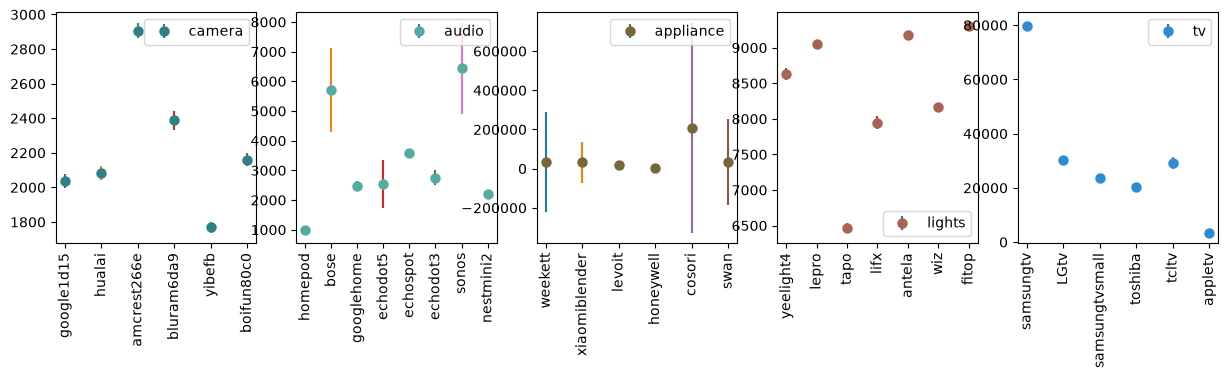

,Minutes,samples,μ,σ,CV
google1d15,40 m 59 s,2315,2037 mW,42,2%
hualai,40 m 60 s,2321,2083 mW,39,2%
amcrest266e,40 m 60 s,2308,2907 mW,45,2%
bluram6da9,40 m 59 s,2312,2389 mW,56,2%
yibefb,40 m 59 s,2318,1770 mW,33,2%
boifun80c0,40 m 59 s,2321,2160 mW,37,2%
homepod,40 m 59 s,2316,975 mW,78,8%
bose,40 m 60 s,2314,5707 mW,1410,25%
googlehome,40 m 59 s,2313,2473 mW,158,6%
echodot5,40 m 60 s,2321,2538 mW,802,32%


In [8]:
#| label: plot1
devices_flat = [x for xs in devices.values() for x in xs]
times = []
means = []
stds = []
samples = []
fig,ax = plt.subplots(1,5)

categories_labels = []
for i, (device, df) in enumerate(get_data().items()):


    category = devices_to_cat[device]
    if category in categories_labels:
        category_label = f'_{category}'
    else:
        category_label = category
    categories_labels.append(category)
    colour = ColorHash(devices_to_cat[device]).hex

    mean = df.power_mW.mean()
    std = df.power_mW.std()
    times.append(df.timestamp.iat[-1] - df.timestamp[0])
    means.append(mean)
    stds.append(std)
    samples.append(len(df))
   
    ax[categories.index(category)].errorbar(device, mean, std, linestyle='none', markersize=15, markerfacecolor=colour, markeredgecolor='none', marker=".", label=category_label)


width = 15
ratio = 0.2
fig.set_figwidth(width)
fig.set_figheight(width * ratio)


means = np.array(means)
stds = np.array(stds)
for i in range(5):
    ax[i].tick_params('x', rotation=90)
    ax[i].legend()
plt.show()

def my_style(styler):
    styler.format(lambda v: f'{v.total_seconds() / 60:.0f} m {v.total_seconds() % 60:.0f} s', 'minutes')
    styler.format(lambda v: f'{v:.0f} mW', subset='means')
    styler.format(lambda v: f'{v:.0f}', subset='std')
    styler.format(lambda v: f'{v * 100:.0f}%', subset='cv')
    styler.relabel_index(["Minutes", "samples", "μ", "σ", "CV"], axis="columns")
    return styler

results = pd.DataFrame(index=devices_flat, data={ "minutes": times, 'samples': samples, 'means': means, 'std': stds, 'cv': stds/means})
results.style.pipe(my_style)



/tmp/ipykernel_21663/2779033125.py:72: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg= numberline.legend(loc='center left', bbox_to_anchor=(1, 0.5),prop={'size': 10}, ncol=3)
/tmp/ipykernel_21663/2779033125.py:81: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig_numberline.tight_layout(rect=(0.025, 0, 1, 1))


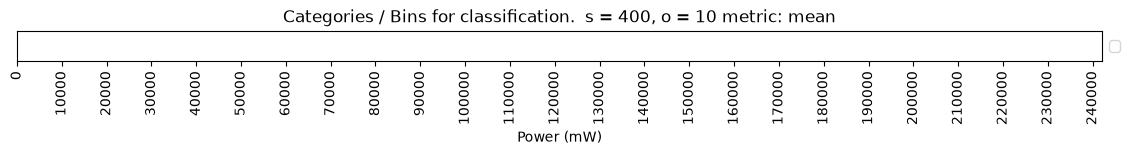

/tmp/ipykernel_21663/2779033125.py:72: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg= numberline.legend(loc='center left', bbox_to_anchor=(1, 0.5),prop={'size': 10}, ncol=3)
/tmp/ipykernel_21663/2779033125.py:81: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig_numberline.tight_layout(rect=(0.025, 0, 1, 1))


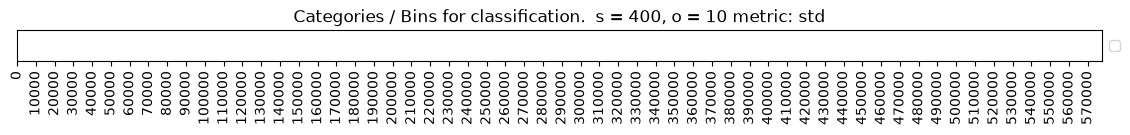

In [14]:
#| label: profiles
# function to compute profiles

# then function to score them

# then existing graph_profiles

# compute overlap% 
# more samples -> less sensitivity
def graph_profiles(data, samples, offset, metric='mean'):
    # get the profiles for the metric, sorted size of spread
    results = sort_dict_by_value({device: profile(df, samples, offset)[metric] for device, df in data.items() }, reverse=True, key=lambda x: x[1][-1] - x[1][0])
    fig_numberline, numberline = plt.subplots(1, 1)
    numberline.set_title(f"Categories / Bins for classification.  s = {samples}, o = {offset} metric: {metric}")

    height = 0.2

    # get the highest value so we know the xlim
    xlim = max(results.values(), key=lambda x: x[-1])[-1] + 1000
    pad_width = 2000
    # overlaps is an list of lists of tuples. 
    # the inner list is the covered ranges for this level
    # greedily assign to largest items?
    # pad out widths to account for annotation

    overlaps = [[]]
    rects = []

    for device, result in results.items():
        # numberline.bar(x=i, height=(result[1] + result[0]) / 2)width = 1
        width = result[-1] - result[0]

        if width < pad_width:
            pad = (pad_width - width) / 2
            maybe_padded = pd.Interval(left=result[0] - pad, right=result[-1] + pad)
        else:
            maybe_padded = result
        # print(device, width, maybe_padded[1] - maybe_padded[0], result, maybe_padded)


        # dev_colour = ColorHash(device).hex

        # # TODO bugs here?
        # for level_num, level in enumerate(overlaps):
        #     for range in level:
        #         if range.overlaps(maybe_padded):
        #             break
        #     else:
        #         overlaps[level_num].append(maybe_padded)
        #         level = level_num
        #         break
        # else:
        #     if level_num > 5:
        #         overlaps[4].append(result)
        #         level = 5
        #     else:
        #         overlaps.append([result])
        #         level = level_num + 1


        # y = height * (level)
    
        # rect = numberline.add_patch(patches.Rectangle((result[0], y), width, height, edgecolor=dev_colour, label=device, hatch_linewidth=1, fill=False, hatchcolor=ColorHash(devices_to_cat[device]).hex, linewidth=3, hatch='ooo'))
        # rects.append(rect)
        # annot = numberline.annotate(f'{device} {width:.0f} {maybe_padded[1] - maybe_padded[0]}', ((result[0] + result[1]) / 2, y + height / 2), size=8, va='center', ha='center', backgroundcolor=dev_colour, rotation=90, color='white')
   
    numberline.tick_params('x', rotation=90)
    numberline.set_yticks([])
    levels = len(overlaps)
    numberline.set_xlim(0, xlim)
    numberline.set_ylim(0, levels * height)
    leg= numberline.legend(loc='center left', bbox_to_anchor=(1, 0.5),prop={'size': 10}, ncol=3)

    numberline.set_xticks(np.arange(0, round(xlim, -3), 10000))

    if metric == 'mean':
        numberline.set_xlabel("Power (mW)")
    fig_numberline.set_figwidth(14)
    fig_numberline.set_figheight(2 * levels * height)
    fig_numberline.canvas.toolbar_visible = True
    fig_numberline.tight_layout(rect=(0.025, 0, 1, 1))

    map_legend_to_ax = {}

    for legend_line, ax_line in zip(leg.get_patches(), rects):
        legend_line.set_picker(5)  # Enable picking on the legend line.
        map_legend_to_ax[legend_line] = ax_line
    plt.show()

# exclude=['cosori', 'samsungtv', 'xiaomiblender', 'swan']
graph_profiles(get_data(), 400, 10)
graph_profiles(get_data(), 400, 10, metric='std')


  Method absolute overlap  distinguishability
0   Mean                x  33 / 33, (100.00%)
1    Std                x   13 / 33, (39.39%)
2   Both                x                   x


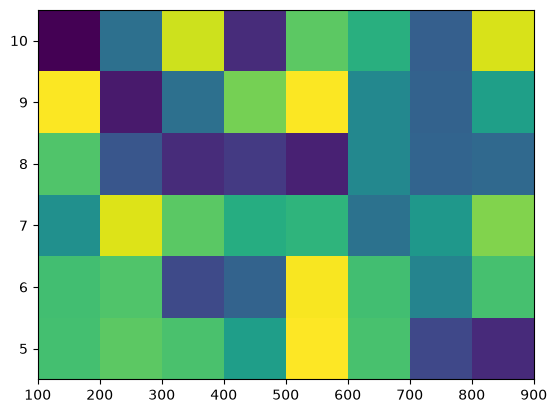

In [ ]:
#| label: evaluation

# Todo more direct export to typst table. maybe a decorator?

# Evaluate methods across all devices, both by total overlap and number of seperatable devices
# use pcolormesh to show the colormesh of the effectiveness when params are varied
"""
Find overlapping intervals, return the number of non-overlapping intervals and the total amount of overlap.

A faster algorithm would place all on same numberline, then it's like the brackets problem. n log n
Do naive n^2 algo for now.

For 2d overlaps, do both? Any overlap counts.

>>> overlap((pd.Interval(left=1, right=3), pd.Interval(left=2, right=4), pd.Interval(left=10, right=20)))
1
"""
def overlap(intervals, metrics=['mean']):
    # TODO: look at multiple metrics here
    for i in range(len(metrics)):
        pass
    # compare the two metrics for the same thing

    independents = 0
    for i, interval in enumerate(intervals):
        independent = True 
        for j, compare in enumerate(intervals):
            if i != j:
                if interval.overlaps(compare):
                    independent = False
        if independent:
            independents += 1

    return independents
                


def compute_overlap(data, samples, offset, metric='mean'):
    if metric == 'both':
        # TODO: do n dimensional overlaps here 
        # need to do the comparison together, otherwise will 
        pass

    results = sort_dict_by_value({device: profile(df, samples, offset)[metric] for device, df in data.items() }, reverse=True, key=lambda x: x[1].right - x[1].left)

    end = list(results.values())[0].left
    start = list(results.values())[-1].right
    # for i in np.linspace(start, end, 1000):
    #     overlap = 0
    #     for device, result in results.items():
    #         if 
   
    return overlap(results.values())

num_devices = len(devices_flat)
mean = compute_overlap(get_data(), 400, 10)
std = compute_overlap(get_data(), 400, 10, metric='std')

# compute the overlap to grade the quality of the profile, ideally you want 0% overlap for ato be valid.
# Both total overlap and known overlap?
print(pd.DataFrame(data={"Method": ["Mean", "Std", "Both"], "absolute overlap": ["x", "x", "x"], "distinguishability": [f"{mean} / {num_devices}, ({mean / num_devices:.2%})", f"{std} / {num_devices}, ({std / num_devices:.2%})", "x"]}))

np.random.seed(19680801)
Z = np.random.rand(6, 8)
x = np.arange(100, 1000, 100)  # len = 11
y = np.arange(4.5, 11, 1)
fig, ax = plt.subplots()
ax.pcolormesh(x, y, Z)

In [ ]:
import doctest
doctest.testmod(verbose=True)

Trying:
    overlap((pd.Interval(left=1, right=3), pd.Interval(left=2, right=4), pd.Interval(left=10, right=20)))
Expecting:
    1
ok
12 items had no tests:
    __main__.State
    __main__.compute_overlap
    __main__.get_data
    __main__.get_dataframe
    __main__.graph_profiles
    __main__.intervalise
    __main__.my_style
    __main__.overlap
    __main__.plot
    __main__.profile
    __main__.sort_dict_by_value
    __main__.window
1 item passed all tests:
   1 test in __main__
1 test in 13 items.
1 passed.
Test passed.


TestResults(failed=0, attempted=1)